# Forgetting through the lens of internal features

The LMEnt setup shows a **learning-forgetting** phenomenon: as training proceeds a
fact can be recalled correctly, then lost, then relearned. This notebook asks
*what happens inside the model* when a fact is forgotten, using the internal
features extracted at **all 13 checkpoints** (15-shot, top-10%% exposure, 1452
facts):

```
feature_extraction/eval_checkpoints.py --num-shots 15 --no-hidden \
    --steps 50000 ... 658032 --top-shared-chunks-pct 10 \
    --output-dir .../15shot_trajectory_top10_internal
```

Each fact now has a **trajectory** of internal signals -- gold-answer probability
and rank, the answer margin, predictive entropy, and the logit-lens resolution
depth -- alongside the binary `correct`. The guiding questions:

1. Do the internals track the wobbling recall curve?
2. Is a fact that is *about to be forgotten* already different, internally, while
   it is still correct?
3. When the flip happens, is it a **cliff** or was the fact always fragile?
4. Is forgetting a loss of **internal knowledge** (retrieval) or only of the
   **readout** (the right answer is there but not emitted)?
5. Can an internal signal *predict* forgetting a checkpoint ahead?

In [9]:
import glob, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# --- visual style (matches the other notebooks) ---
INK, INK2, GRID, SURF = "#0b0b0b", "#52514e", "#e6e5e1", "#fcfcfb"
BLUE, ORANGE, RED, NEUTRAL = "#2a78d6", "#eb6834", "#e34948", "#f0efec"
plt.rcParams.update({
    "figure.dpi": 130,
    "figure.facecolor": SURF, "axes.facecolor": SURF, "savefig.facecolor": SURF,
    "text.color": INK, "axes.labelcolor": INK2, "axes.titlecolor": INK,
    "xtick.color": INK2, "ytick.color": INK2, "xtick.labelsize": 9, "ytick.labelsize": 9,
    "axes.edgecolor": GRID, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "font.size": 10, "axes.titlesize": 11, "legend.frameon": False,
})
C_SURV, C_FORG = BLUE, ORANGE      # will-survive vs will-forget
pfmt = lambda v, p: f"{v:.0%}"

TRAJ_DIR = "data/artifacts/recall/rotemab_15shot_top10_internal"
files = sorted(glob.glob(f"{TRAJ_DIR}/*.parquet"),
               key=lambda f: int(re.search(r"step(\d+)", f).group(1)))
steps = [int(re.search(r"step(\d+)", f).group(1)) for f in files]
FEATURES = ["correct", "is_top1", "gold_prob", "answer_margin", "gold_rank",
            "pred_entropy", "resolution_depth"]

# Long panel over never-excluded facts (excluded is a property of the fact, so the
# set is identical at every checkpoint).
frames = []
for f, s in zip(files, steps):
    d = pd.read_parquet(f)
    d = d[~d["excluded"]].copy()
    d["step"] = s
    frames.append(d[["id", "step"] + FEATURES])
long = pd.concat(frames, ignore_index=True)

# One (n_facts x n_steps) matrix per feature, columns ordered by step.
P = {c: long.pivot(index="id", columns="step", values=c).reindex(columns=steps)
     for c in FEATURES}
ids = P["correct"].index
correct = P["correct"].to_numpy().astype(bool)          # (n, 13)
n_facts, n_steps = correct.shape

# relation type + exposure, aligned to the panel
props = pd.read_csv("15_shot_top_10_trajectory_with_fact_properites.csv")
props = props.set_index("id").reindex(ids)
prop = props["prop"].to_numpy()
exposure = props["num_shared_chunks"].to_numpy()

print(f"{n_facts} facts x {n_steps} checkpoints")
print(f"accuracy: {correct[:,0].mean():.1%} @ {steps[0]//1000}k  ->  "
      f"{correct[:,-1].mean():.1%} @ {steps[-1]//1000}k")
forget_transitions = ((correct[:, :-1]) & (~correct[:, 1:])).sum()
print(f"forgetting transitions (correct->wrong): {int(forget_transitions)}")

1310 facts x 13 checkpoints
accuracy: 14.4% @ 50k  ->  41.5% @ 658k
forgetting transitions (correct->wrong): 1003


## 1 — Internals track the wobbling recall curve

Recall (`correct`, `is_top1`) rises overall but dips several times -- the
learning-forgetting signature. The internal confidence of the facts that *are*
correct moves with it: the same checkpoints that lose accuracy also show lower
median gold probability and a more negative answer margin. We plot fractions and
confidence in separate panels (never on a shared axis).

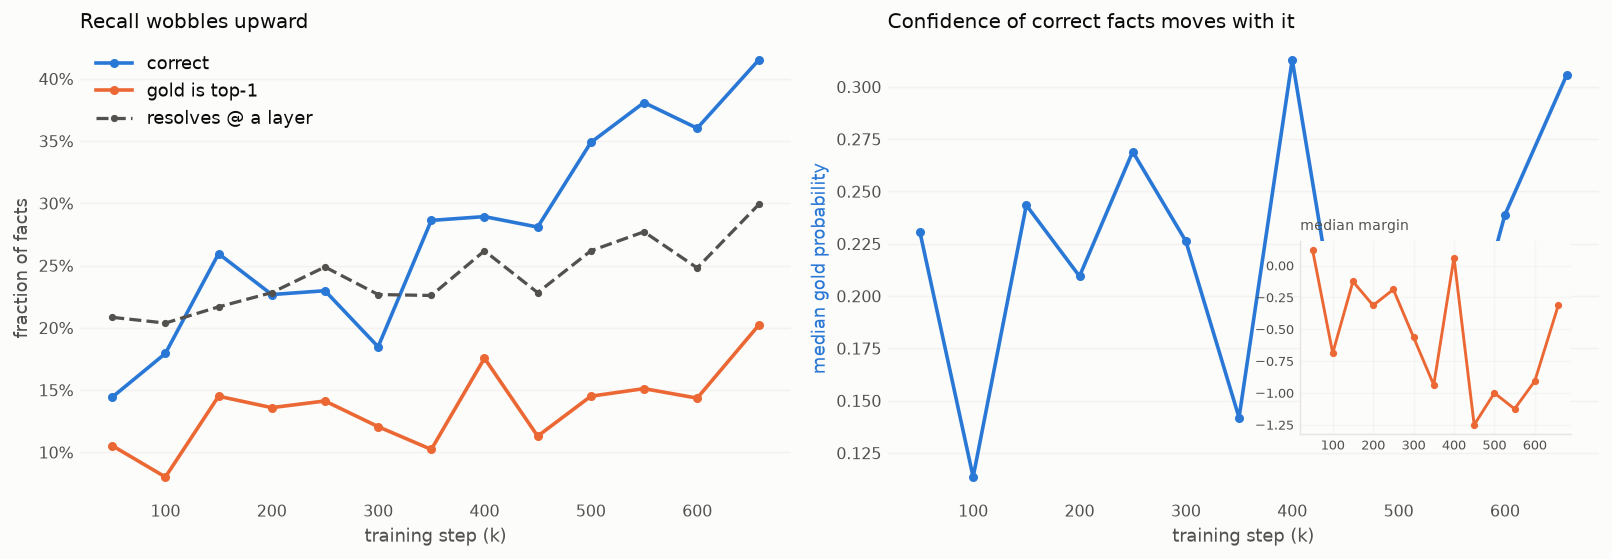

In [10]:
xk = [s / 1000 for s in steps]
frac_correct = correct.mean(axis=0)
frac_top1 = P["is_top1"].to_numpy().mean(axis=0)
frac_resolve = (~np.isnan(P["resolution_depth"].to_numpy())).mean(axis=0)

# confidence among the facts correct at each checkpoint
gp = P["gold_prob"].to_numpy(); am = P["answer_margin"].to_numpy()
med_gp = np.array([np.nanmedian(gp[correct[:, t], t]) for t in range(n_steps)])
med_am = np.array([np.nanmedian(am[correct[:, t], t]) for t in range(n_steps)])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.5, 4.4))
ax1.plot(xk, frac_correct, color=BLUE, lw=2, marker="o", ms=4, label="correct")
ax1.plot(xk, frac_top1, color=ORANGE, lw=2, marker="o", ms=4, label="gold is top-1")
ax1.plot(xk, frac_resolve, color=INK2, lw=1.8, marker="o", ms=3, ls="--",
         label="resolves @ a layer")
ax1.yaxis.set_major_formatter(plt.FuncFormatter(pfmt))
ax1.set_ylabel("fraction of facts")
ax1.set_title("Recall wobbles upward", loc="left")
ax1.legend(loc="upper left")

ax2.plot(xk, med_gp, color=BLUE, lw=2, marker="o", ms=4, label="median gold prob.")
ax2b = ax2  # single axis; margin plotted on twin-free secondary via normalization
ax2.set_ylabel("median gold probability", color=BLUE)
ax2.set_title("Confidence of correct facts moves with it", loc="left")
# answer margin shares the story but has a different scale -> its own small panel
axin = ax2.inset_axes([0.58, 0.14, 0.38, 0.42])
axin.plot(xk, med_am, color=ORANGE, lw=1.6, marker="o", ms=3)
axin.set_title("median margin", fontsize=8, color=INK2, loc="left")
axin.tick_params(labelsize=7, length=0)
axin.grid(alpha=0.3)

for ax in (ax1, ax2):
    ax.set_xlabel("training step (k)")
    ax.grid(axis="y", alpha=0.4)
    ax.tick_params(length=0)
    for s in ax.spines.values():
        s.set_visible(False)
fig.tight_layout()

## 2 — Forgetting strikes fragile facts

Take every checkpoint at which a fact is **correct**, and split by what happens
next: does it **survive** to the next checkpoint or get **forgotten**? Comparing
the internal signals *at the current (still-correct) checkpoint* shows the two
groups are already far apart. A fact about to be forgotten is only marginally
correct -- low gold probability, a strongly negative margin, and a gold rank that
is near, but not at, 1.

1003 forget vs 3151 survive events


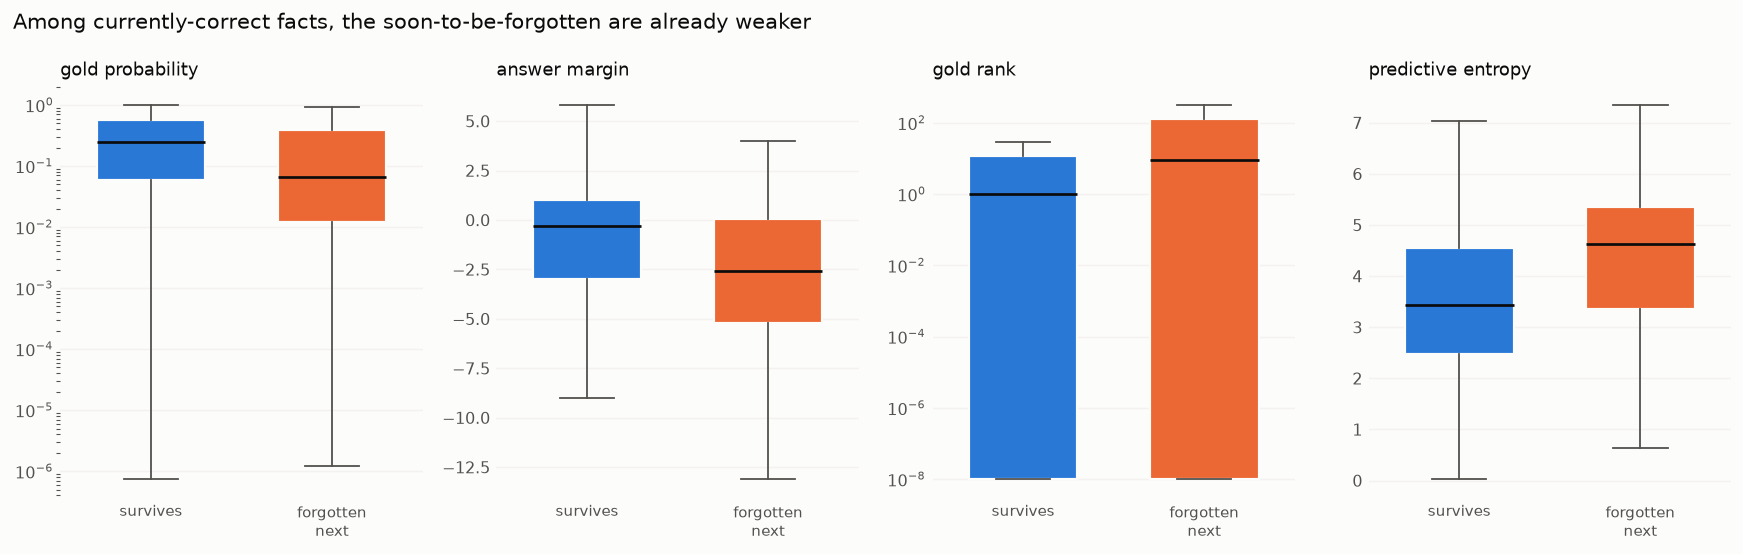

In [11]:
# gather currently-correct observations, labelled by next-step outcome
rows = {k: [] for k in ["gold_prob", "answer_margin", "gold_rank", "pred_entropy"]}
label_forget = []
for t in range(n_steps - 1):
    cur = correct[:, t]
    if not cur.any():
        continue
    for k in rows:
        rows[k].append(P[k].to_numpy()[cur, t])
    label_forget.append(~correct[cur, t + 1])
for k in rows:
    rows[k] = np.concatenate(rows[k])
label_forget = np.concatenate(label_forget)

PANELS = [("gold_prob", "gold probability", True),
          ("answer_margin", "answer margin", False),
          ("gold_rank", "gold rank", True),
          ("pred_entropy", "predictive entropy", False)]
fig, axes = plt.subplots(1, 4, figsize=(13.5, 4.3))
for ax, (k, label, log) in zip(axes, PANELS):
    v = rows[k]
    surv = v[~label_forget]; forg = v[label_forget]
    if log:
        surv = np.clip(surv, 1e-8, None); forg = np.clip(forg, 1e-8, None)
    bp = ax.boxplot([surv, forg], patch_artist=True, widths=0.6, showfliers=False,
                    medianprops=dict(color=INK, lw=1.5),
                    whiskerprops=dict(color=INK2), capprops=dict(color=INK2))
    for patch, col in zip(bp["boxes"], (C_SURV, C_FORG)):
        patch.set_facecolor(col); patch.set_edgecolor(SURF); patch.set_linewidth(1.2)
    if log:
        ax.set_yscale("log")
    ax.set_xticks([1, 2], ["survives", "forgotten\nnext"], fontsize=8.5)
    ax.set_title(label, loc="left", fontsize=10)
    ax.grid(axis="y", alpha=0.4); ax.tick_params(length=0)
    for s in ax.spines.values():
        s.set_visible(False)
fig.suptitle("Among currently-correct facts, the soon-to-be-forgotten are already weaker",
             x=0.01, ha="left", fontsize=11.5)
fig.tight_layout()
print(f"{label_forget.sum()} forget vs {(~label_forget).sum()} survive events")

## 3 — No cliff: forgotten facts were fragile all along

Aligning on the forgetting event (τ = 0 is the last correct checkpoint, τ = +1 the
first wrong one) shows the internal confidence of these facts is **flat and low**
across the whole window -- there is no sharp collapse at the flip. They hover near
the decision boundary and tip over. The dashed line is the median for facts that
stay correct: a different regime entirely.

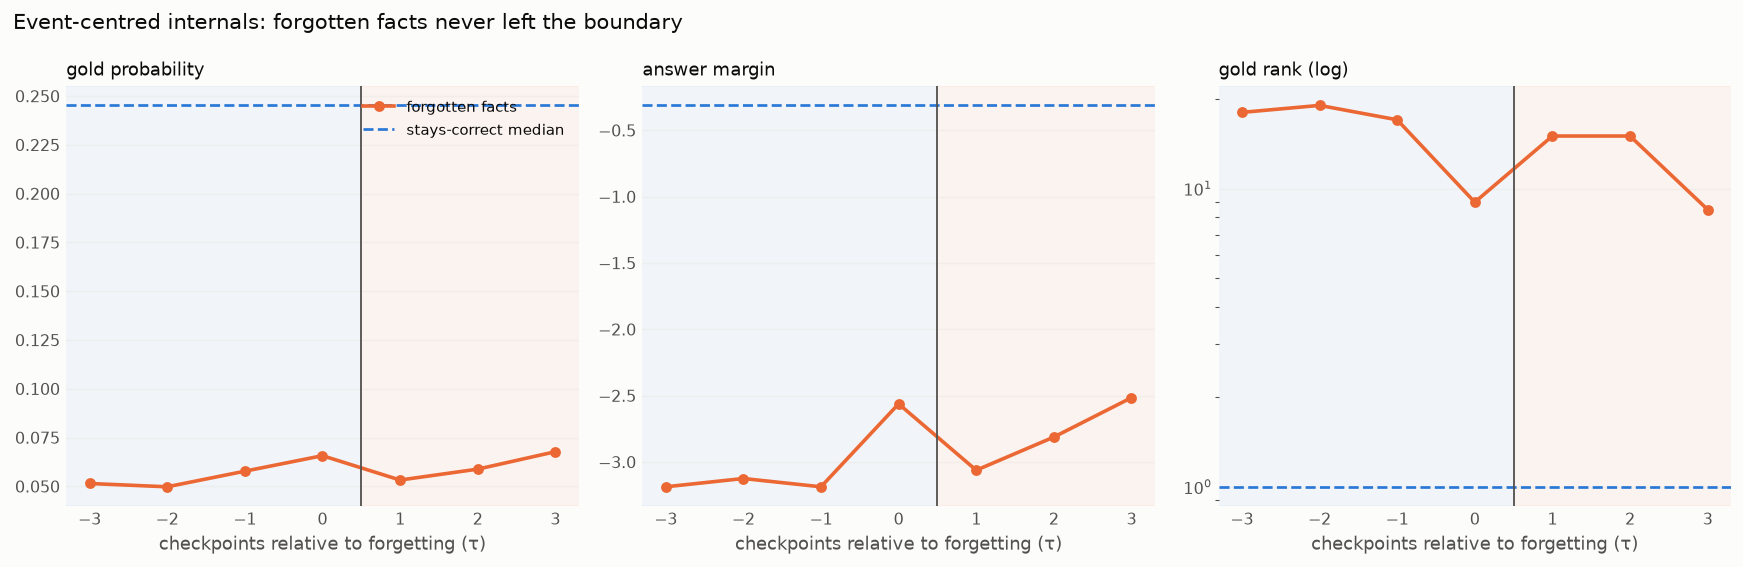

In [12]:
offsets = range(-3, 4)
def event_curve(feat):
    M = P[feat].to_numpy()
    med = {}
    for tau in offsets:
        vals = []
        for t in range(n_steps - 1):
            forget = correct[:, t] & (~correct[:, t + 1])
            j = t + tau
            if 0 <= j < n_steps:
                vals.append(M[forget, j])
        med[tau] = np.nanmedian(np.concatenate(vals)) if vals else np.nan
    return np.array([med[o] for o in offsets])

# survivor reference: median among currently-correct-and-surviving
surv_ref = {k: np.nanmedian(rows[k][~label_forget]) for k in
            ["gold_prob", "answer_margin", "gold_rank"]}

CURVES = [("gold_prob", "gold probability", False),
          ("answer_margin", "answer margin", False),
          ("gold_rank", "gold rank (log)", True)]
xo = list(offsets)
fig, axes = plt.subplots(1, 3, figsize=(13.5, 4.4))
for ax, (k, label, log) in zip(axes, CURVES):
    y = event_curve(k)
    ax.axvspan(-3.5, 0.5, color=BLUE, alpha=0.05)      # labelled correct
    ax.axvspan(0.5, 3.5, color=ORANGE, alpha=0.06)     # labelled wrong
    ax.plot(xo, y, color=C_FORG, lw=2, marker="o", ms=5, label="forgotten facts")
    ax.axhline(surv_ref[k], color=C_SURV, ls="--", lw=1.5, label="stays-correct median")
    ax.axvline(0.5, color=INK2, lw=1)
    if log:
        ax.set_yscale("log")
    ax.set_xlim(-3.3, 3.3)
    ax.set_xlabel("checkpoints relative to forgetting (τ)")
    ax.set_title(label, loc="left", fontsize=10)
    ax.grid(axis="y", alpha=0.4); ax.tick_params(length=0)
    for s in ax.spines.values():
        s.set_visible(False)
axes[0].legend(loc="upper right", fontsize=8.5)
fig.suptitle("Event-centred internals: forgotten facts never left the boundary",
             x=0.01, ha="left", fontsize=11.5)
fig.tight_layout()

## 4 — Retrieval failure or readout failure?

At the flip, is the answer *gone from the model* or just *not emitted*? For the
forgotten facts we compare the last-correct checkpoint (τ = 0) with the first-wrong
one (τ = +1). Both the output signal (`is_top1`) and the internal one (still
resolves at some layer) drop -- but note how **low they already are at τ = 0**:
most of these facts were correct by the lenient substring match without gold ever
being the top token or resolving internally. Forgetting is mostly the tipping of
facts that were **never robustly stored**, not the erasure of solid knowledge.

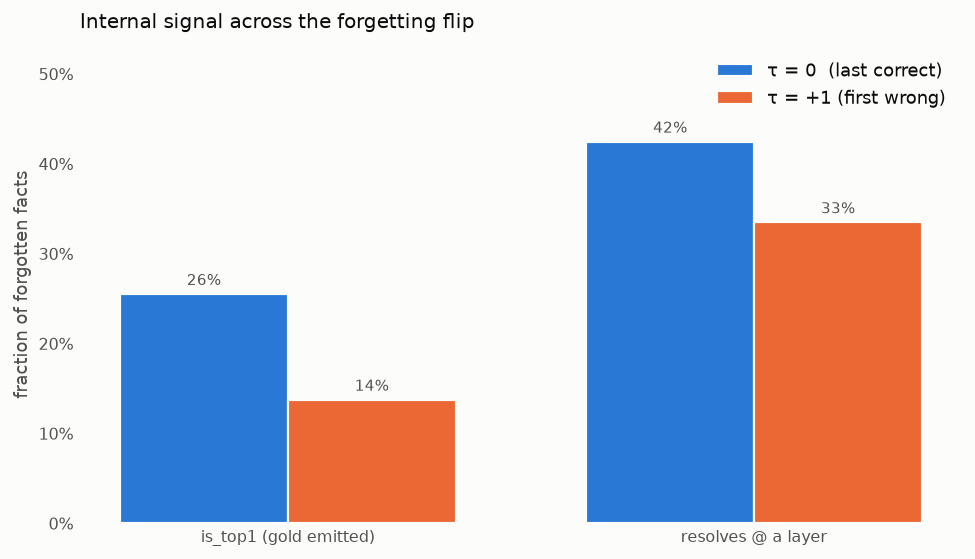

In [13]:
def rate_at(mask_feat, tau, kind):
    vals = []
    M = P[mask_feat].to_numpy()
    for t in range(n_steps - 1):
        forget = correct[:, t] & (~correct[:, t + 1])
        j = t + tau
        if 0 <= j < n_steps:
            col = M[forget, j]
            if kind == "resolve":
                vals.append(~np.isnan(col))
            else:
                vals.append(col.astype(float))
    return np.nanmean(np.concatenate(vals))

metrics = ["is_top1 (gold emitted)", "resolves @ a layer"]
at0 = [rate_at("is_top1", 0, "bool"), rate_at("resolution_depth", 0, "resolve")]
at1 = [rate_at("is_top1", 1, "bool"), rate_at("resolution_depth", 1, "resolve")]

fig, ax = plt.subplots(figsize=(7.6, 4.4))
x = np.arange(len(metrics)); w = 0.36
ax.bar(x - w/2, at0, w, color=BLUE, edgecolor=SURF, linewidth=1.2,
       label="τ = 0  (last correct)")
ax.bar(x + w/2, at1, w, color=ORANGE, edgecolor=SURF, linewidth=1.2,
       label="τ = +1 (first wrong)")
for xi, (a, b) in enumerate(zip(at0, at1)):
    ax.text(xi - w/2, a + 0.01, f"{a:.0%}", ha="center", fontsize=8.5, color=INK2)
    ax.text(xi + w/2, b + 0.01, f"{b:.0%}", ha="center", fontsize=8.5, color=INK2)
ax.set_xticks(x, metrics)
ax.set_ylim(0, max(at0 + at1) * 1.25)
ax.yaxis.set_major_formatter(plt.FuncFormatter(pfmt))
ax.set_ylabel("fraction of forgotten facts")
ax.set_title("Internal signal across the forgetting flip", loc="left", pad=10)
ax.legend(loc="upper right"); ax.tick_params(length=0)
for s in ax.spines.values():
    s.set_visible(False)
fig.tight_layout()

## 5 — Internal confidence predicts forgetting a checkpoint ahead

Putting it together: bin every currently-correct observation by its gold
probability and measure how often it is forgotten at the next checkpoint. The
relationship is monotonic -- the weakest decile is forgotten ~3x as often as the
strongest. A single scalar (gold probability, or the answer margin) gives a real,
if modest, one-step-ahead warning (AUC ≈ 0.64); being top-1 roughly halves the
risk.

AUC  gold_prob -> forget      : 0.638
AUC  answer_margin -> forget  : 0.632
P(forget | gold is top-1)     : 18.9%
P(forget | gold not top-1)    : 32.6%


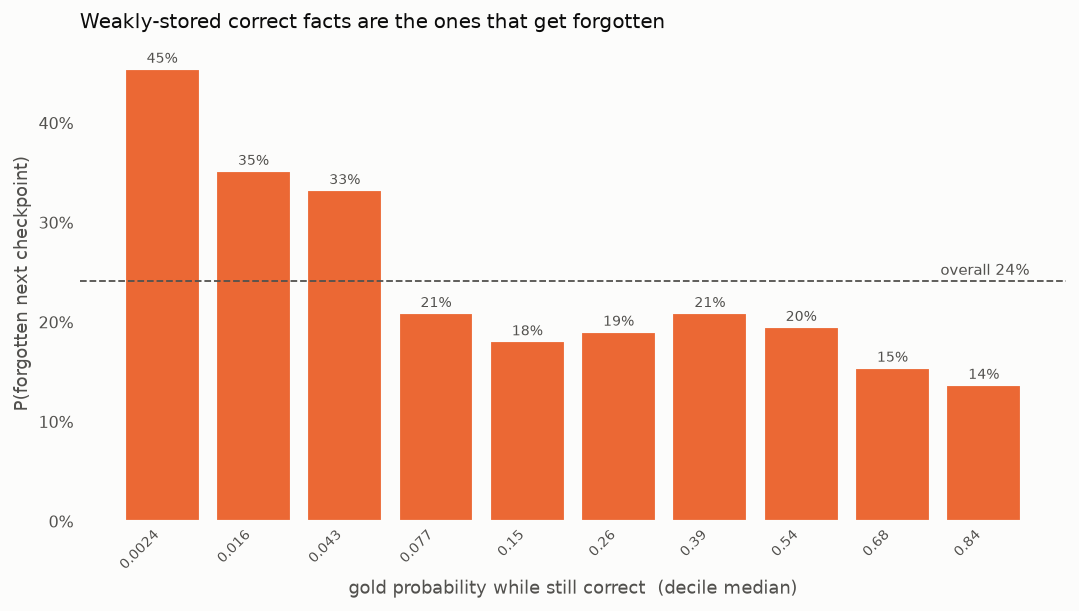

In [14]:
from scipy.stats import rankdata
def auc(score, y):                       # P(score ranks a positive above a negative)
    m = ~np.isnan(score)
    score, y = score[m], y[m].astype(bool)
    r = rankdata(score)
    n1 = y.sum(); n0 = (~y).sum()
    return (r[y].sum() - n1 * (n1 + 1) / 2) / (n1 * n0)

gpv = rows["gold_prob"]; amv = rows["answer_margin"]
auc_gp = auc(-gpv, label_forget)          # lower prob -> more likely forgotten
auc_am = auc(-amv, label_forget)

m = ~np.isnan(gpv)
dec = pd.qcut(gpv[m], 10, labels=False, duplicates="drop")
lab = label_forget[m]
gpm = gpv[m]
p_forget = np.array([lab[dec == d].mean() for d in range(dec.max() + 1)])
gp_med = np.array([np.median(gpm[dec == d]) for d in range(dec.max() + 1)])

fig, ax = plt.subplots(figsize=(8.4, 4.8))
xb = np.arange(len(p_forget))
ax.bar(xb, p_forget, color=ORANGE, edgecolor=SURF, linewidth=1.2, width=0.82)
for i, v in enumerate(p_forget):
    ax.text(i, v + 0.006, f"{v:.0%}", ha="center", fontsize=8, color=INK2)
ax.axhline(label_forget.mean(), color=INK2, ls="--", lw=1)
ax.text(len(p_forget) - 0.5, label_forget.mean() + 0.006,
        f"overall {label_forget.mean():.0%}", ha="right", fontsize=8.5, color=INK2)
ax.set_xticks(xb, [f"{v:.2g}" for v in gp_med], rotation=45, ha="right", fontsize=8)
ax.set_xlabel("gold probability while still correct  (decile median)")
ax.yaxis.set_major_formatter(plt.FuncFormatter(pfmt))
ax.set_ylabel("P(forgotten next checkpoint)")
ax.set_title("Weakly-stored correct facts are the ones that get forgotten",
             loc="left", pad=10)
ax.tick_params(length=0)
for s in ax.spines.values():
    s.set_visible(False)
fig.tight_layout()

print(f"AUC  gold_prob -> forget      : {auc_gp:.3f}")
print(f"AUC  answer_margin -> forget  : {auc_am:.3f}")
print(f"P(forget | gold is top-1)     : {label_forget[rows['gold_rank']==1].mean():.1%}")
print(f"P(forget | gold not top-1)    : {label_forget[rows['gold_rank']>1].mean():.1%}")

## 6 — Forgetting by relation type

Does the fragility story play out differently across relations? We measure a
per-relation **forgetting hazard** -- the probability that a fact correct at one
checkpoint is wrong at the next, pooled over all checkpoints -- and connect it to
the same internal signal used above.

- **6a** ranks relations by hazard. Some are stable (`capital`, `capital of` ~17%),
  others churn constantly (`genre`, `country` > 60%). Relations with few correct
  observations are greyed out -- their hazard is noisy.
- **6b** shows *when* each relation wobbles: a checkpoint-by-checkpoint accuracy
  heatmap. Stable relations stay dark across training; volatile ones flicker.
- **6c** ties it back to the mechanism: relations whose correct facts are stored
  with low gold probability (fragile) have the highest hazard -- the same
  weak-storage → forgetting link as at the per-fact level, now across relations.

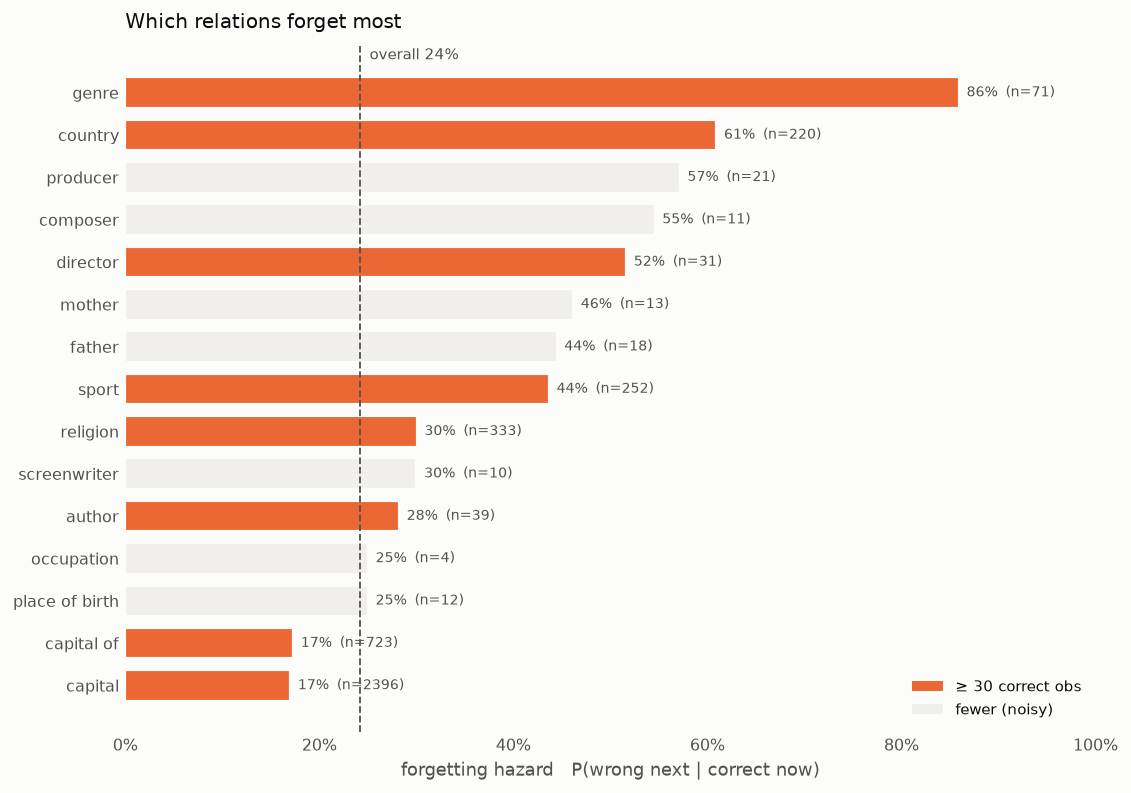

In [15]:
# 6a — forgetting hazard by relation type
# hazard = P(wrong next checkpoint | correct now), pooled over all checkpoints.
MIN_OBS = 30                       # a relation needs this many correct (fact,ckpt) obs to be reliable
gp_all = P["gold_prob"].to_numpy()
recs = []
for p in np.unique(prop):
    m = prop == p
    cur = correct[m, :-1]; nxt = correct[m, 1:]
    n_obs = int(cur.sum())                                   # correct (fact, ckpt) observations
    gpc = gp_all[m, :][correct[m, :]]
    recs.append(dict(prop=p, n_facts=int(m.sum()), n_obs=n_obs,
                     hazard=(cur & ~nxt).sum() / n_obs if n_obs else np.nan,
                     gp_correct=np.nanmedian(gpc) if len(gpc) else np.nan,
                     exposure=np.median(exposure[m])))
prop_stats = pd.DataFrame(recs).sort_values("hazard").reset_index(drop=True)
overall_hz = (correct[:, :-1] & ~correct[:, 1:]).sum() / correct[:, :-1].sum()

fig, ax = plt.subplots(figsize=(8.8, 6.2))
yp = np.arange(len(prop_stats))
reliable = prop_stats["n_obs"] >= MIN_OBS
ax.barh(yp, prop_stats["hazard"],
        color=[ORANGE if r else NEUTRAL for r in reliable],
        edgecolor=SURF, linewidth=1.2, height=0.72)
for i, row in prop_stats.iterrows():
    ax.text(row["hazard"] + 0.008, i, f"{row['hazard']:.0%}  (n={row['n_obs']})",
            va="center", fontsize=8, color=INK2)
ax.axvline(overall_hz, color=INK2, ls="--", lw=1)
ax.text(overall_hz, len(prop_stats) - 0.3, f"  overall {overall_hz:.0%}",
        color=INK2, fontsize=8.5, va="bottom")
ax.set_yticks(yp, prop_stats["prop"], fontsize=9)
ax.set_xlim(0, 1)
ax.xaxis.set_major_formatter(plt.FuncFormatter(pfmt))
ax.set_xlabel("forgetting hazard   P(wrong next | correct now)")
ax.set_title("Which relations forget most", loc="left", pad=10)
ax.tick_params(length=0)
for s in ax.spines.values():
    s.set_visible(False)
from matplotlib.patches import Patch
ax.legend(handles=[Patch(facecolor=ORANGE, label=f"≥ {MIN_OBS} correct obs"),
                   Patch(facecolor=NEUTRAL, label="fewer (noisy)")],
          loc="lower right", fontsize=8.5)
fig.tight_layout()

Most stable: capital (17%), capital of (17%), author (28%).
Most volatile: genre (86%), country (61%), producer (57%).
Relations with fewer than 30 correct observations (occupation, screenwriter, composer, mother, …) are greyed out and labeled with their n, since their hazard is noisy.

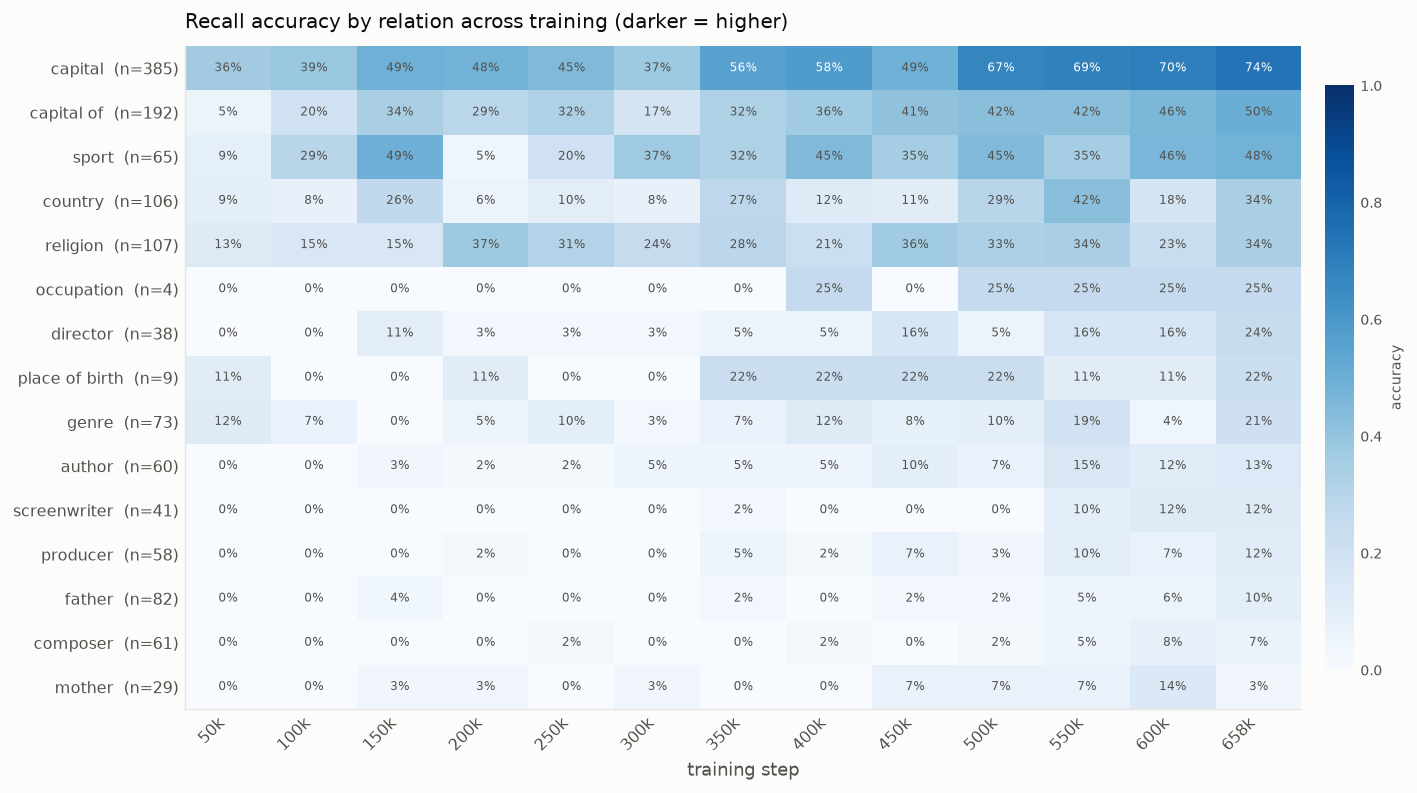

In [16]:
# 6b — when each relation wobbles: accuracy heatmap across training
props_u = np.unique(prop)
acc = np.array([[correct[prop == p, t].mean() for t in range(n_steps)]
                for p in props_u])
row_order = np.argsort(-acc[:, -1])            # most-recalled relations on top
acc = acc[row_order]; props_u = props_u[row_order]

fig, ax = plt.subplots(figsize=(11, 6.2))
im = ax.imshow(acc, aspect="auto", cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(n_steps), [f"{s//1000}k" for s in steps], rotation=45, ha="right")
ax.set_yticks(range(len(props_u)),
              [f"{p}  (n={(prop==p).sum()})" for p in props_u], fontsize=9)
for i in range(acc.shape[0]):
    for j in range(acc.shape[1]):
        v = acc[i, j]
        ax.text(j, i, f"{v:.0%}", ha="center", va="center", fontsize=6.5,
                color="white" if v > 0.55 else INK2)
ax.set_xlabel("training step")
ax.set_title("Recall accuracy by relation across training (darker = higher)",
             loc="left", pad=10)
ax.tick_params(length=0)
cb = fig.colorbar(im, ax=ax, fraction=0.025, pad=0.02)
cb.set_label("accuracy", fontsize=8); cb.outline.set_visible(False)
cb.ax.tick_params(length=0, labelsize=8)
fig.tight_layout()

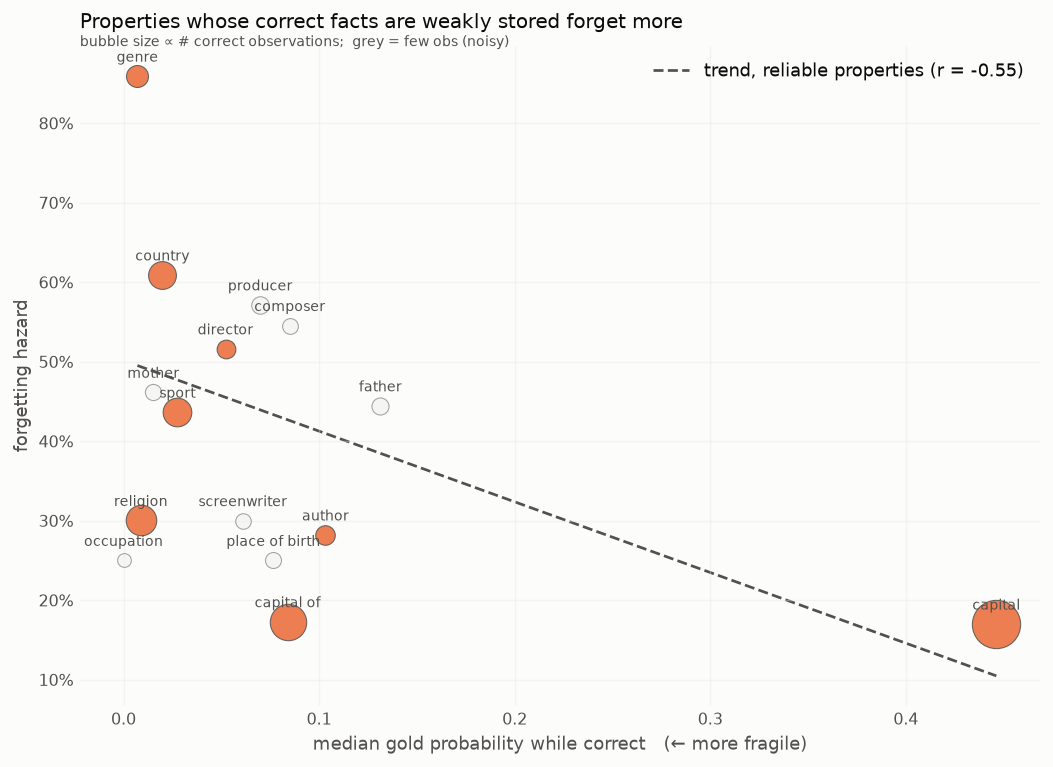

In [17]:
# 6c — the fragility mechanism holds across relations
rel = prop_stats[prop_stats["n_obs"] >= MIN_OBS]      # fit only where hazard is reliable
b, a = np.polyfit(rel["gp_correct"], rel["hazard"], 1)
r = np.corrcoef(rel["gp_correct"], rel["hazard"])[0, 1]
xs = np.linspace(rel["gp_correct"].min(), rel["gp_correct"].max(), 40)

fig, ax = plt.subplots(figsize=(8.2, 6))
ax.plot(xs, a + b * xs, color=INK2, ls="--", lw=1.5, zorder=1,
        label=f"trend, reliable properties (r = {r:.2f})")
for _, row in prop_stats.iterrows():
    reli = row["n_obs"] >= MIN_OBS
    ax.scatter(row["gp_correct"], row["hazard"],
               s=np.sqrt(row["n_obs"]) * 14 + 30,
               color=ORANGE if reli else NEUTRAL, alpha=0.85 if reli else 0.5,
               edgecolor=INK2, linewidth=0.6, zorder=2)
    ax.annotate(row["prop"], (row["gp_correct"], row["hazard"]), fontsize=7.5,
                color=INK2, xytext=(0, 8), textcoords="offset points", ha="center")
ax.yaxis.set_major_formatter(plt.FuncFormatter(pfmt))
ax.set_xlabel("median gold probability while correct   (← more fragile)")
ax.set_ylabel("forgetting hazard")
ax.set_title("Properties whose correct facts are weakly stored forget more",
             loc="left", pad=10)
ax.grid(alpha=0.35)
ax.legend(loc="upper right")
ax.text(0.0, 1, "bubble size ∝ # correct observations;  grey = few obs (noisy)",
        transform=ax.transAxes, fontsize=8, color=INK2)
ax.tick_params(length=0)
for s in ax.spines.values():
    s.set_visible(False)
fig.tight_layout()